In [1]:
import os
import numpy as np
import librosa
import json
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ===== CONFIG =====
MODEL_PATH = "model_2.h5"
LABELS_PATH = "labels_2.json"
DATASET_PATH = r"C:\Users\ADMIN\Desktop\Sukriti\VIT\SL\AnuAssistant\dataset"

SAMPLE_RATE = 22050
N_MFCC = 20
MAX_PAD_LEN = 40

# ===== LOAD MODEL =====
model = load_model(MODEL_PATH)

with open(LABELS_PATH, "r") as f:
    labels = json.load(f)

index_to_label = {v: k for k, v in labels.items()}

# ===== PREPROCESS =====
def preprocess_audio(file_path):
    audio, sr = librosa.load(file_path, sr=SAMPLE_RATE)

    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=N_MFCC)

    if mfcc.shape[1] < MAX_PAD_LEN:
        pad_width = MAX_PAD_LEN - mfcc.shape[1]
        mfcc = np.pad(mfcc, ((0,0),(0,pad_width)), mode='constant')
    else:
        mfcc = mfcc[:, :MAX_PAD_LEN]

    mfcc = (mfcc - np.mean(mfcc)) / (np.std(mfcc) + 1e-6)
    mfcc = mfcc.reshape(1, N_MFCC, MAX_PAD_LEN, 1)

    return mfcc

# ===== LOAD DATA =====
y_true = []
y_pred = []

print("📂 Evaluating dataset...")

for label_name, label_index in labels.items():
    folder_path = os.path.join(DATASET_PATH, label_name)

    for file in os.listdir(folder_path):
        if file.lower().endswith(".wav"):
            file_path = os.path.join(folder_path, file)

            try:
                features = preprocess_audio(file_path)

                prediction = model.predict(features, verbose=0)
                pred_index = np.argmax(prediction)

                y_true.append(label_index)
                y_pred.append(pred_index)

            except Exception as e:
                print(f"❌ Error: {file_path}")

# ===== RESULTS =====
print("\n🎯 Accuracy:")
print(accuracy_score(y_true, y_pred))

print("\n📊 Classification Report:")
print(classification_report(y_true, y_pred, target_names=list(labels.keys())))

print("\n📉 Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

📂 Evaluating dataset...

🎯 Accuracy:
0.8711711711711712

📊 Classification Report:
                  precision    recall  f1-score   support

             anu       0.74      0.86      0.79       318
   close browser       0.86      0.89      0.88       324
close calculator       0.94      0.81      0.87       324
            help       0.90      0.94      0.92       318
            mute       0.71      0.92      0.80       288
            next       0.90      0.87      0.89       318
    open browser       0.89      0.80      0.84       318
 open calculator       0.88      0.87      0.87       324
           pause       0.90      0.89      0.90       318
            play       0.93      0.89      0.91       318
        previous       0.82      0.91      0.86       318
      screenshot       0.93      0.86      0.89       318
           sleep       0.95      0.86      0.90       318
          unmute       0.94      0.84      0.89       318

        accuracy                           0.8

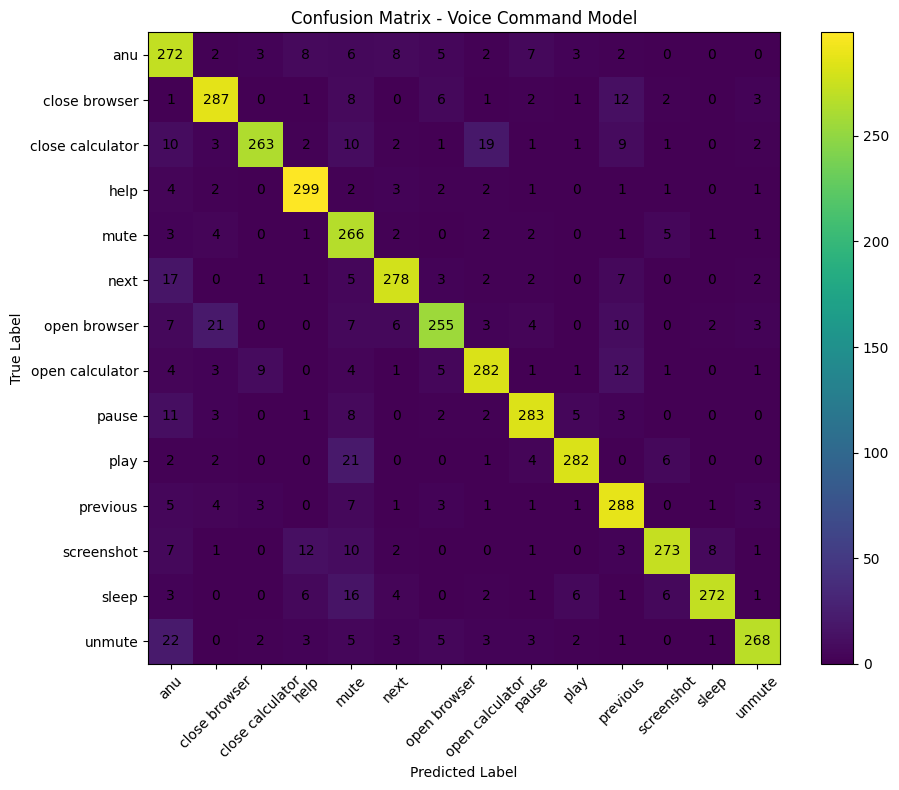

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

# Convert one-hot if needed
if len(y_true[0:1]) and isinstance(y_true[0], (list, np.ndarray)):
    y_true_labels = np.argmax(y_true, axis=1)
else:
    y_true_labels = y_true

if len(y_pred[0:1]) and isinstance(y_pred[0], (list, np.ndarray)):
    y_pred_labels = np.argmax(y_pred, axis=1)
else:
    y_pred_labels = y_pred

# Compute confusion matrix
cm = confusion_matrix(y_true_labels, y_pred_labels)

# Plot
plt.figure(figsize=(10, 8))
plt.imshow(cm)
plt.title("Confusion Matrix - Voice Command Model")
plt.colorbar()

# Axis labels
classes = list(labels.keys())
tick_marks = np.arange(len(classes))

plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Add numbers inside cells
for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center")

plt.tight_layout()
plt.show()